# Building Permit Delays: Classification Models
Loads the saved 70/30 split from `data/split/` (created in `02_eda_train_test_split.ipynb`) and compares five classification algorithms.
Target: `on_time` (1 = processed within 85 days, 0 = delayed).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
SEED = 42

In [2]:
# Loading the saved split
PROJECT_ROOT = Path("..")
SPLIT_DIR = PROJECT_ROOT / "data" / "split"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(SPLIT_DIR / "train.csv")
test = pd.read_csv(SPLIT_DIR / "test.csv")
print("Train:", train.shape, "| Test:", test.shape)

Train: (33206, 10) | Test: (14232, 10)


In [3]:
# Feature list
USE_YEAR = True    # set to False later to re-run the models without created_year

CAT_FEATURES = ["type_of_work", "property_use", "area", "permit_category"]
NUM_FEATURES = ["log_value", "value_is_zero", "has_contractor", "created_month"]
if USE_YEAR:
    NUM_FEATURES.append("created_year")

FEATURES = CAT_FEATURES + NUM_FEATURES
TARGET = "on_time"

assert "elapsed_days" not in FEATURES and TARGET not in FEATURES
print(len(FEATURES), "features:", FEATURES)

9 features: ['type_of_work', 'property_use', 'area', 'permit_category', 'log_value', 'value_is_zero', 'has_contractor', 'created_month', 'created_year']


In [4]:
# Building X and y
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("On-time share  train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

X_train: (33206, 9) | X_test: (14232, 9)
On-time share  train: 0.5118 | test: 0.5117


In [5]:
# Preprocessing
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
])

## 4. Classification Models
All models use the same saved 70/30 split, the same `preprocess` step and the same evaluation function.

**Evaluation**
- 5-fold stratified cross-validation on the **training set** (stability check).
- Final scores on the **test set**, used once per model: accuracy, macro F1, ROC-AUC, and precision, recall and F1 for both classes.
- Confusion matrix and ROC curve for every model.

### 4.1 Logistic Regression (baseline)

In [6]:
# Shared Evaluation Function
results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluate_model(name, pipe, plot=True):
    # 1) Stability check: cross-validation on the training set only
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro", "roc_auc"], n_jobs=1)
    # 2) Fit on the full training set, score once on the test set
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=[0, 1])

    row = {
        "Model": name,
        "CV AUC (mean)": cv_res["test_roc_auc"].mean(),
        "CV AUC (std)": cv_res["test_roc_auc"].std(),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Macro F1": f1_score(y_test, pred, average="macro"),
        "Test ROC-AUC": roc_auc_score(y_test, prob),
        "Precision (delayed)": p[0], "Recall (delayed)": r[0], "F1 (delayed)": f[0],
        "Precision (on time)": p[1], "Recall (on time)": r[1], "F1 (on time)": f[1],
    }
    results.append(row)

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"wspace": 0.3})
        ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                               display_labels=["Delayed", "On time"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
        ax[0].set_title(f"{name}: confusion matrix (test set)", pad=12)
        ax[0].grid(False)

        fpr, tpr, _ = roc_curve(y_test, prob)
        ax[1].plot(fpr, tpr, label=f"AUC = {row['Test ROC-AUC']:.3f}")
        ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
        ax[1].set_xlabel("False positive rate")
        ax[1].set_ylabel("True positive rate")
        ax[1].set_title(f"{name}: ROC curve (test set)", pad=12)
        ax[1].legend(loc="lower right")

        plt.savefig(FIG_DIR / f"12_{name.lower().replace(' ', '_')}_eval.png", dpi=150, bbox_inches="tight")
        plt.show()
    return pipe

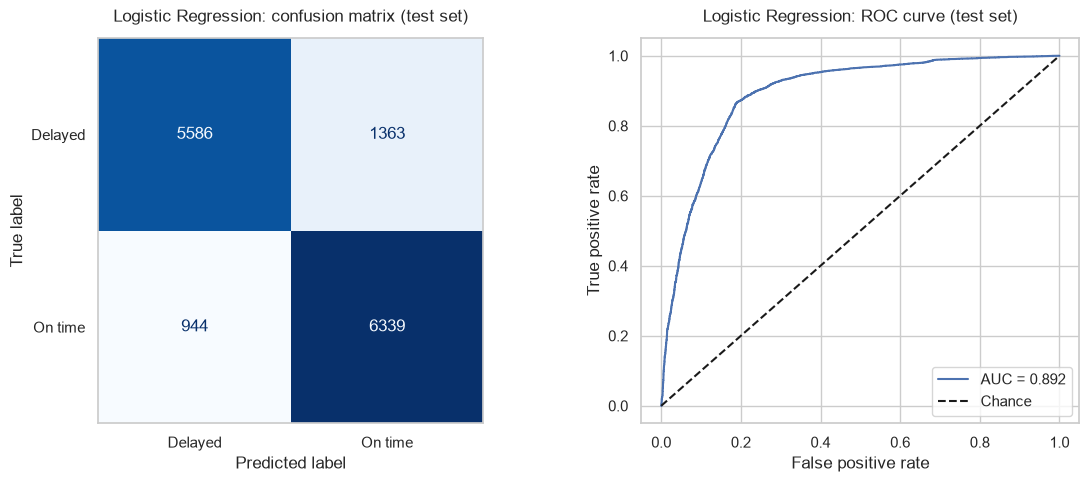

Model,Logistic Regression
CV AUC (mean),0.888
CV AUC (std),0.004
Test Accuracy,0.838
Test Macro F1,0.837
Test ROC-AUC,0.892
Precision (delayed),0.855
Recall (delayed),0.804
F1 (delayed),0.829
Precision (on time),0.823
Recall (on time),0.870


In [7]:
# Running the Logistic Regression and displaying the results table
log_reg = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
log_reg = evaluate_model("Logistic Regression", log_reg)

results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").set_index("Model").round(3)
results_df.T

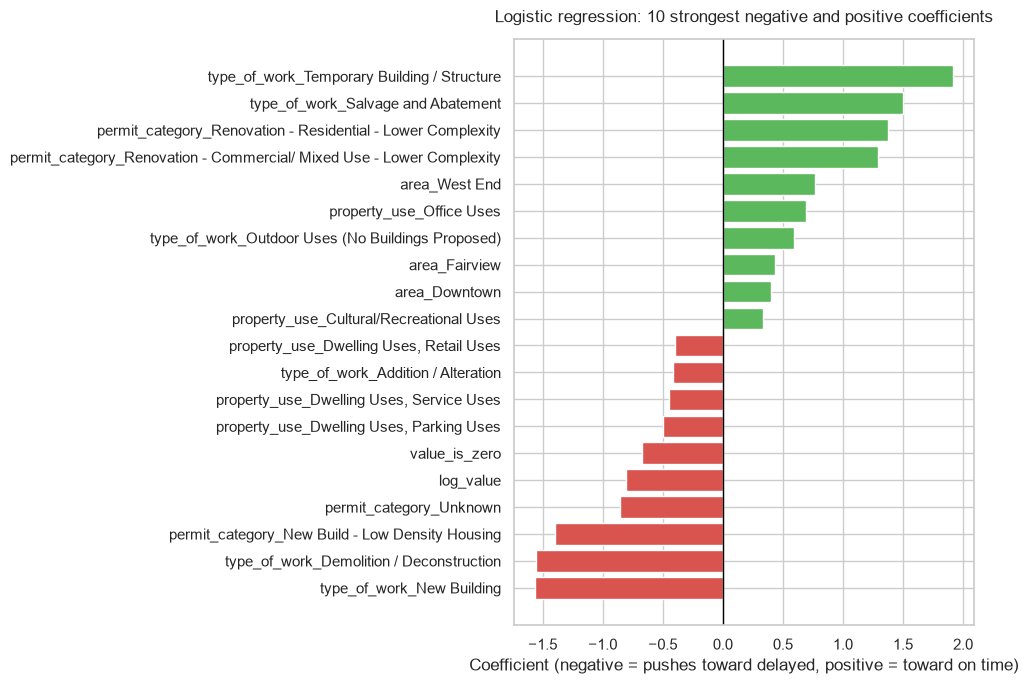

In [8]:
# What the model learned
names = log_reg.named_steps["prep"].get_feature_names_out()
coef = pd.Series(log_reg.named_steps["clf"].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(10), coef.tail(10)])

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index.str.replace("cat__", "").str.replace("num__", ""), top.values,
        color=["#d9534f" if v < 0 else "#5cb85c" for v in top.values])
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Logistic regression: 10 strongest negative and positive coefficients", pad=12)
ax.set_xlabel("Coefficient (negative = pushes toward delayed, positive = toward on time)")
plt.tight_layout()
plt.savefig(FIG_DIR / "13_logreg_coefficients.png", dpi=150)
plt.show()

### 4.2 Decision Tree
A decision tree splits the permits with a series of yes/no questions (for example "is the work a New Building?").
1. Showing that an unrestricted tree overfits.
2. Choosing the depth with cross-validation on the training set.
3. Tuning the tree with a grid search (scored by ROC-AUC).
4. Evaluating the best tree once on the test set, then look at which features it relies on.

In [9]:
# First running the unrestricted tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV

tree_full = Pipeline([("prep", preprocess),
                      ("clf", DecisionTreeClassifier(random_state=SEED))]).fit(X_train, y_train)

print("Depth reached:", tree_full.named_steps["clf"].get_depth())
print("Train accuracy:", round(accuracy_score(y_train, tree_full.predict(X_train)), 3))
print("Test accuracy: ", round(accuracy_score(y_test, tree_full.predict(X_test)), 3))
# We can see that it overfits

Depth reached: 47
Train accuracy: 0.977
Test accuracy:  0.785


##### The gap shows the tree memorised the training data, so it's a case of overfitting. So tuning is needed.

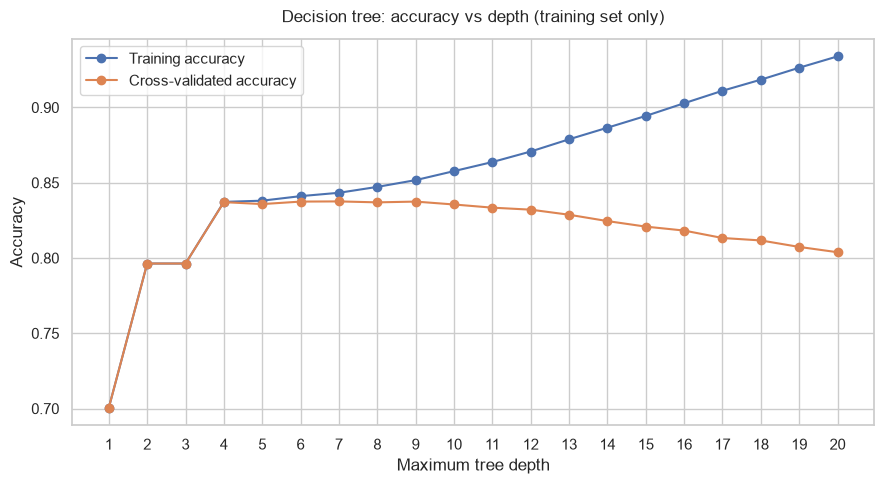

In [10]:
# Accuracy v/s tree depth
rows = []
for d in range(1, 21):
    p = Pipeline([("prep", preprocess),
                  ("clf", DecisionTreeClassifier(max_depth=d, random_state=SEED))])
    r = cross_validate(p, X_train, y_train, cv=cv, scoring="accuracy",
                       return_train_score=True, n_jobs=1)
    rows.append((d, r["train_score"].mean(), r["test_score"].mean()))
curve = pd.DataFrame(rows, columns=["depth", "train", "cv"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve["depth"], curve["train"], marker="o", label="Training accuracy")
ax.plot(curve["depth"], curve["cv"], marker="o", label="Cross-validated accuracy")
ax.set_xticks(range(1, 21))
ax.set_xlabel("Maximum tree depth")
ax.set_ylabel("Accuracy")
ax.set_title("Decision tree: accuracy vs depth (training set only)", pad=12)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "14_tree_depth_curve.png", dpi=150)
plt.show()

##### As we can see, cross-validated accuracy rises to about 0.838 around depth 7 and then slowly decline, while the training accuracy keeps climbing. That divergence is overfitting.

In [11]:
# Grid Search
param_grid = {
    "clf__max_depth": [4, 6, 8, 10, 12, 15],
    "clf__min_samples_leaf": [1, 10, 30, 50],
    "clf__criterion": ["gini", "entropy"],
}
grid = GridSearchCV(
    Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(random_state=SEED))]),
    param_grid, cv=cv, scoring="roc_auc", n_jobs=1,
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))

Best parameters: {'clf__criterion': 'gini', 'clf__max_depth': 15, 'clf__min_samples_leaf': 50}
Best CV ROC-AUC: 0.903


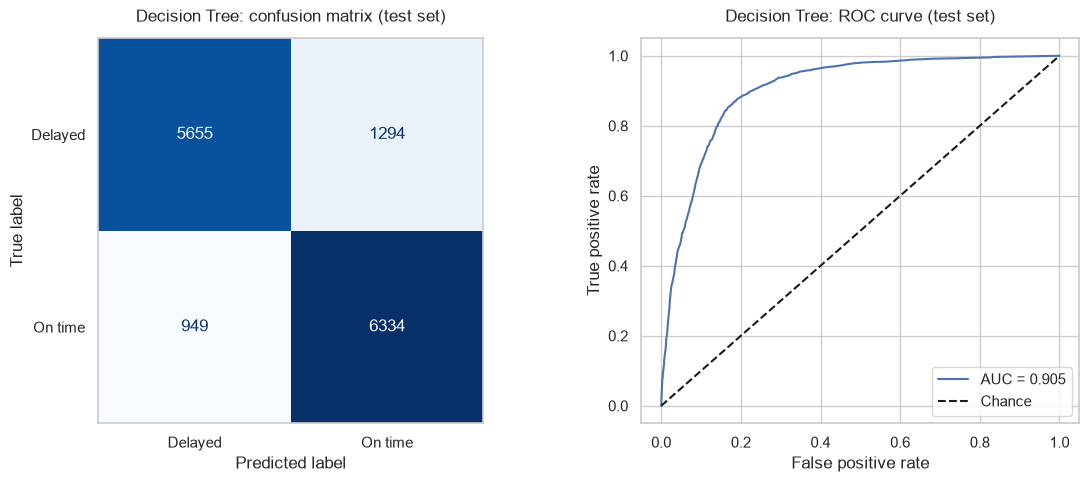

Model,Logistic Regression,Decision Tree
CV AUC (mean),0.888,0.903
CV AUC (std),0.004,0.001
Test Accuracy,0.838,0.842
Test Macro F1,0.837,0.842
Test ROC-AUC,0.892,0.905
Precision (delayed),0.855,0.856
Recall (delayed),0.804,0.814
F1 (delayed),0.829,0.835
Precision (on time),0.823,0.830
Recall (on time),0.870,0.870


In [12]:
# Evaluating the tuned tree
best_tree = evaluate_model("Decision Tree", grid.best_estimator_)

results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").set_index("Model").round(3)
results_df.T

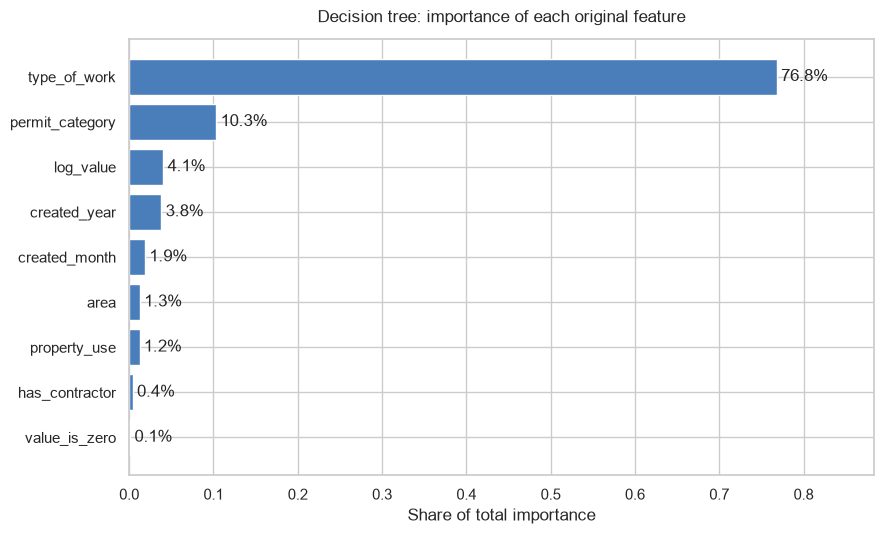

In [13]:
# Feature Importance
names = best_tree.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_tree.named_steps["clf"].feature_importances_, index=names)

def original_feature(name):
    for c in CAT_FEATURES:
        if name.startswith("cat__" + c):
            return c
    return name.replace("num__", "")

grouped = imp.groupby(original_feature).sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(grouped.index, grouped.values, color="#4a7ebb")
for i, v in enumerate(grouped.values):
    ax.text(v + 0.005, i, f"{v:.1%}", va="center")
ax.set_xlim(0, grouped.max() * 1.15)
ax.set_title("Decision tree: importance of each original feature", pad=12)
ax.set_xlabel("Share of total importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "15_tree_feature_importance.png", dpi=150)
plt.show()

### 4.3 Random Forest
A random forest trains many decision trees, each on a random sample of the permits and a random subset of features,
and combines their votes. Averaging many different trees reduces the overfitting a single deep tree suffers from.
1. Train a default forest as a reference.
2. Tune it with a randomized search (12 combinations, 5-fold CV, scored by ROC-AUC) on the training set.
3. Evaluate the best forest once on the test set and compare feature importance with the single tree.

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_default = Pipeline([("prep", preprocess),
                       ("clf", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))])
rf_default.fit(X_train, y_train)

print("Train accuracy:", round(accuracy_score(y_train, rf_default.predict(X_train)), 3))
print("Test accuracy: ", round(accuracy_score(y_test, rf_default.predict(X_test)), 3))
print("Test ROC-AUC:  ", round(roc_auc_score(y_test, rf_default.predict_proba(X_test)[:, 1]), 3))

Train accuracy: 0.977
Test accuracy:  0.837
Test ROC-AUC:   0.904


##### Without limits on its trees, the forest also partly memorises the training data, which is why we tune it.

In [15]:
# Randomized Search
param_dist = {
    "clf__n_estimators": [200, 300],
    "clf__max_depth": [10, 15, 20, 25, None],
    "clf__min_samples_leaf": [1, 5, 10,20,30],
    "clf__max_features": ["sqrt",0.3],
    
    
}
rf_search = RandomizedSearchCV(
    Pipeline([("prep", preprocess), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
    param_dist, n_iter=14, cv=cv, scoring="roc_auc", random_state=SEED, n_jobs=1,
)
rf_search.fit(X_train, y_train)
print("Best parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:", round(rf_search.best_score_, 3))

Best parameters: {'clf__n_estimators': 300, 'clf__min_samples_leaf': 5, 'clf__max_features': 0.3, 'clf__max_depth': 25}
Best CV ROC-AUC: 0.912


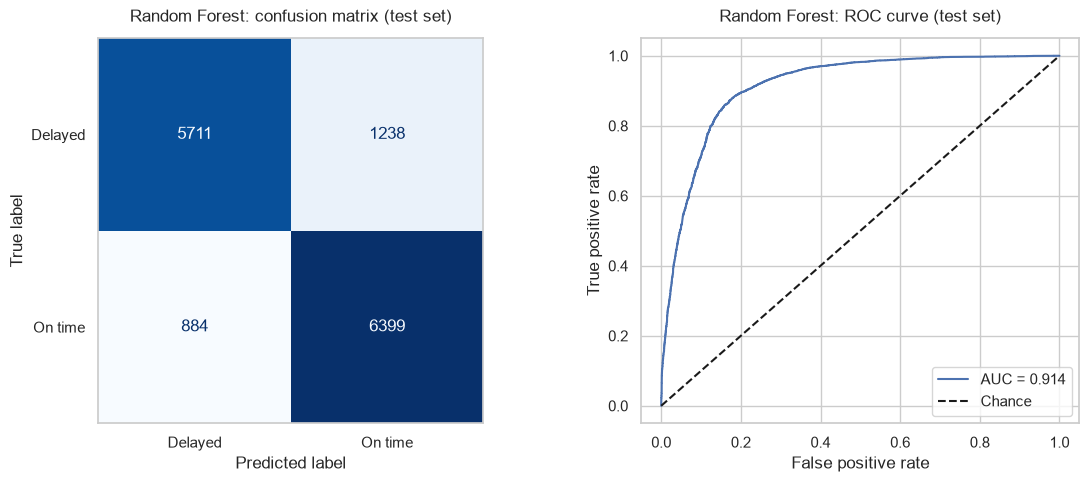

Model,Logistic Regression,Decision Tree,Random Forest
CV AUC (mean),0.888,0.903,0.912
CV AUC (std),0.004,0.001,0.003
Test Accuracy,0.838,0.842,0.851
Test Macro F1,0.837,0.842,0.851
Test ROC-AUC,0.892,0.905,0.914
Precision (delayed),0.855,0.856,0.866
Recall (delayed),0.804,0.814,0.822
F1 (delayed),0.829,0.835,0.843
Precision (on time),0.823,0.830,0.838
Recall (on time),0.870,0.870,0.879


In [16]:
# Evaluating the tuned forest
best_rf = evaluate_model("Random Forest", rf_search.best_estimator_)

results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").set_index("Model").round(3)
results_df.T

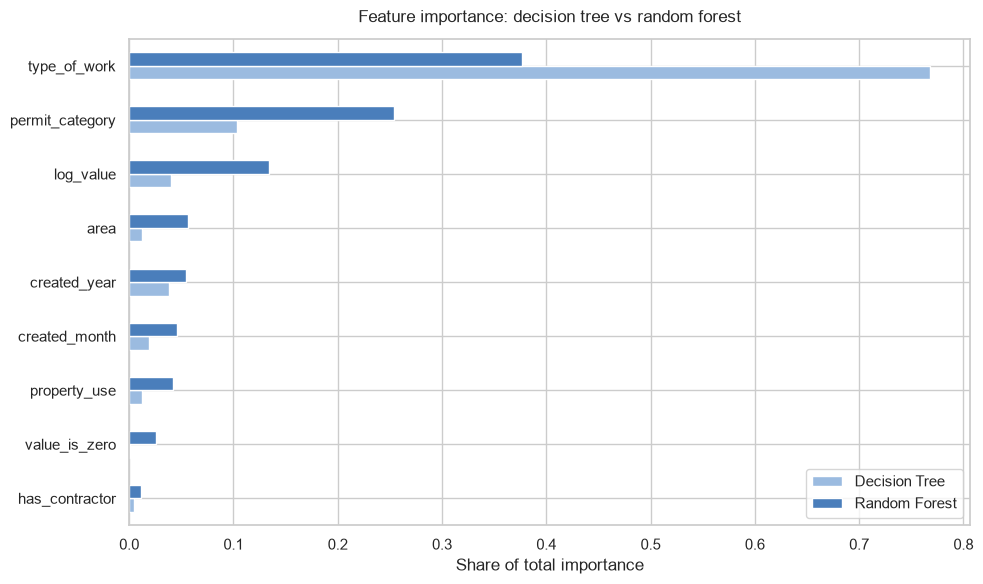

In [17]:
# Feature importance (tree vs forest)
names = best_rf.named_steps["prep"].get_feature_names_out()
rf_imp = pd.Series(best_rf.named_steps["clf"].feature_importances_, index=names)
rf_grouped = rf_imp.groupby(original_feature).sum()

compare = pd.DataFrame({"Decision Tree": grouped, "Random Forest": rf_grouped}).sort_values("Random Forest")

fig, ax = plt.subplots(figsize=(10, 6))
compare.plot.barh(ax=ax, color=["#9bbbe0", "#4a7ebb"])
ax.set_title("Feature importance: decision tree vs random forest", pad=12)
ax.set_xlabel("Share of total importance")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "17_forest_feature_importance.png", dpi=150)
plt.show()

##### The forest spreads importance more evenly than the decision tree, which put 77% on type_of_work. Because each tree only sees a random subset of features (max_features=0.3), the others get a chance to contribute, and that is part of why the forest scores higher.

#### Permutation importance (test set)
Impurity-based importance can favour continuous features and features with many categories.
Permutation importance is a more reliable check: each feature is shuffled in turn on the **test set**,
and we measure how much the test ROC-AUC drops. A bigger drop means the model relies on that feature more.

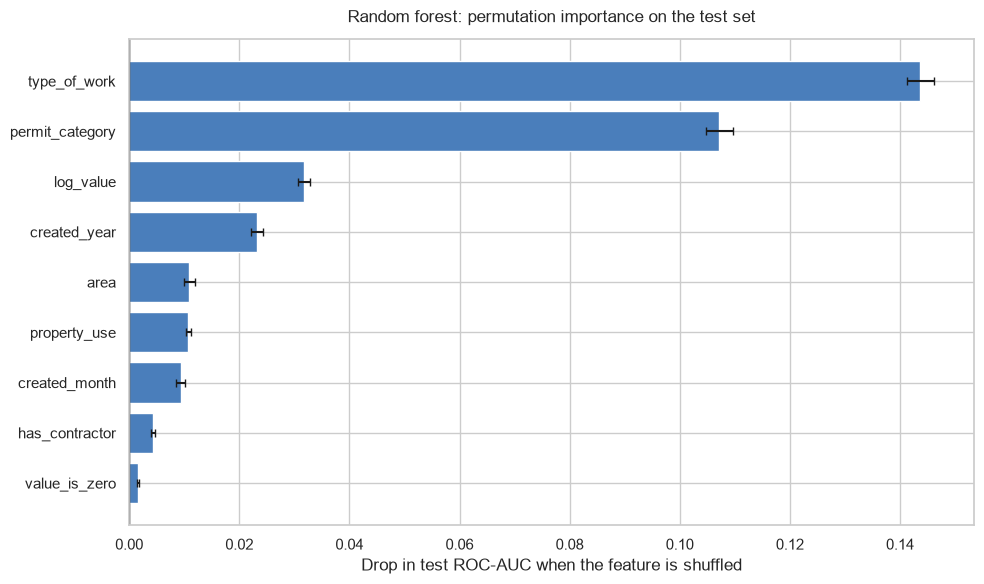

,mean,std
type_of_work,0.1437,0.0024
permit_category,0.1072,0.0024
log_value,0.0318,0.0011
created_year,0.0232,0.0011
area,0.0109,0.0010
property_use,0.0107,0.0004
created_month,0.0093,0.0008
has_contractor,0.0043,0.0004
value_is_zero,0.0016,0.0002


In [18]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=SEED, n_jobs=1)

perm_df = (pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                        index=X_test.columns)
             .sort_values("mean"))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(perm_df.index, perm_df["mean"], xerr=perm_df["std"], color="#4a7ebb", capsize=3)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Random forest: permutation importance on the test set", pad=12)
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
plt.tight_layout()
plt.savefig(FIG_DIR / "18_rf_permutation_importance.png", dpi=150)
plt.show()

perm_df.sort_values("mean", ascending=False).round(4)

### 4.4 Gradient Boosting
Gradient boosting builds trees one after another; each new tree focuses on the permits the previous trees got wrong.
We use scikit-learn's `HistGradientBoostingClassifier`, which handles categorical features natively,
so categories are label-encoded instead of one-hot encoded, and numeric features need no scaling.
Tuned with a randomized search (15 combinations, 5-fold CV, ROC-AUC) on the training set.

In [19]:
# Preprocessing and tuning
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder

# Categories -> integer codes; numeric columns pass through unchanged
preprocess_gb = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), CAT_FEATURES),
    ("num", "passthrough", NUM_FEATURES),
])

gb_dist = {
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_iter": [200, 400, 800],
    "clf__max_leaf_nodes": [15, 31, 63],
    "clf__min_samples_leaf": [20, 50, 100],
    "clf__l2_regularization": [0.0, 1.0],
}
gb_search = RandomizedSearchCV(
    Pipeline([("prep", preprocess_gb),
              ("clf", HistGradientBoostingClassifier(categorical_features=[0, 1, 2, 3],
                                                     early_stopping=False, random_state=SEED))]),
    gb_dist, n_iter=15, cv=cv, scoring="roc_auc", random_state=SEED, n_jobs=1,
)
gb_search.fit(X_train, y_train)

print("Best parameters:", gb_search.best_params_)
print("Best CV ROC-AUC:", round(gb_search.best_score_, 3))

Best parameters: {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 63, 'clf__max_iter': 400, 'clf__learning_rate': 0.03, 'clf__l2_regularization': 0.0}
Best CV ROC-AUC: 0.911


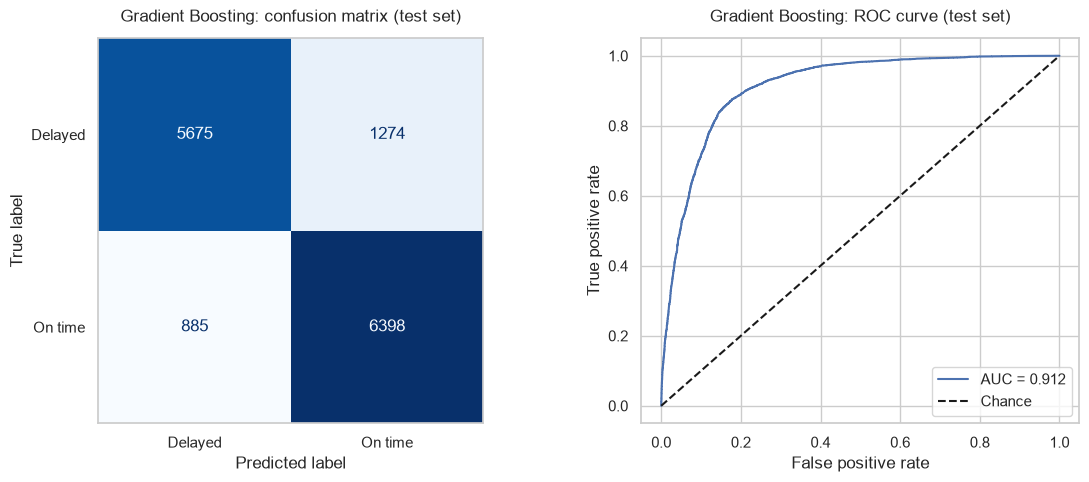

Model,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting
CV AUC (mean),0.888,0.903,0.912,0.911
CV AUC (std),0.004,0.001,0.003,0.003
Test Accuracy,0.838,0.842,0.851,0.848
Test Macro F1,0.837,0.842,0.851,0.848
Test ROC-AUC,0.892,0.905,0.914,0.912
Precision (delayed),0.855,0.856,0.866,0.865
Recall (delayed),0.804,0.814,0.822,0.817
F1 (delayed),0.829,0.835,0.843,0.840
Precision (on time),0.823,0.830,0.838,0.834
Recall (on time),0.870,0.870,0.879,0.878


In [20]:
# Evaluating the gradient boosting model
best_gb = evaluate_model("Gradient Boosting", gb_search.best_estimator_)

results_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last").set_index("Model").round(3)
results_df.T

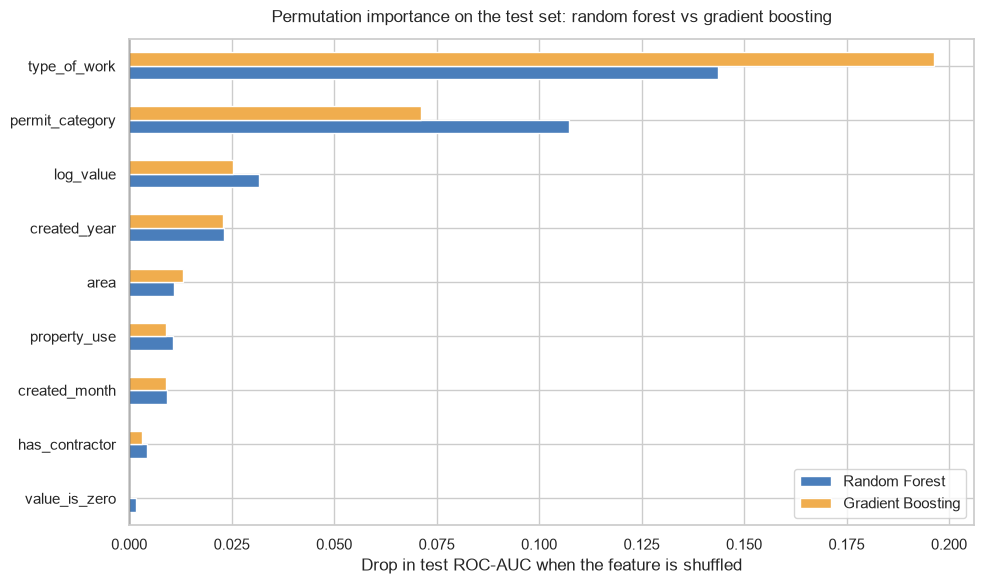

,mean,std
type_of_work,0.1963,0.0033
permit_category,0.0713,0.0016
log_value,0.0253,0.0009
created_year,0.0228,0.0008
area,0.0130,0.0006
created_month,0.0090,0.0007
property_use,0.0089,0.0005
has_contractor,0.0031,0.0003
value_is_zero,0.0001,0.0001


In [21]:
# permutation importance for gradient boosting and comparison with random forest
gb_perm = permutation_importance(best_gb, X_test, y_test, scoring="roc_auc",
                                 n_repeats=10, random_state=SEED, n_jobs=1)

gb_perm_df = pd.DataFrame({"mean": gb_perm.importances_mean, "std": gb_perm.importances_std},
                          index=X_test.columns)

perm_compare = pd.DataFrame({
    "Random Forest": perm_df["mean"],
    "Gradient Boosting": gb_perm_df["mean"],
}).sort_values("Random Forest")

fig, ax = plt.subplots(figsize=(10, 6))
perm_compare.plot.barh(ax=ax, color=["#4a7ebb", "#f0ad4e"])
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Permutation importance on the test set: random forest vs gradient boosting", pad=12)
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "20_perm_importance_rf_vs_gb.png", dpi=150)
plt.show()

gb_perm_df.sort_values("mean", ascending=False).round(4)

### 4.5 Model comparison
All four models are compared on the same test set, alongside two simple baselines:
always predicting the majority class, and predicting from type of work alone.

,Test Accuracy,Test Macro F1,Test ROC-AUC
Baseline: majority class,0.512,0.339,0.500
Baseline: type of work only,0.801,0.796,0.804
Logistic Regression,0.838,0.837,0.892
Decision Tree,0.842,0.842,0.905
Random Forest,0.851,0.851,0.914
Gradient Boosting,0.848,0.848,0.912


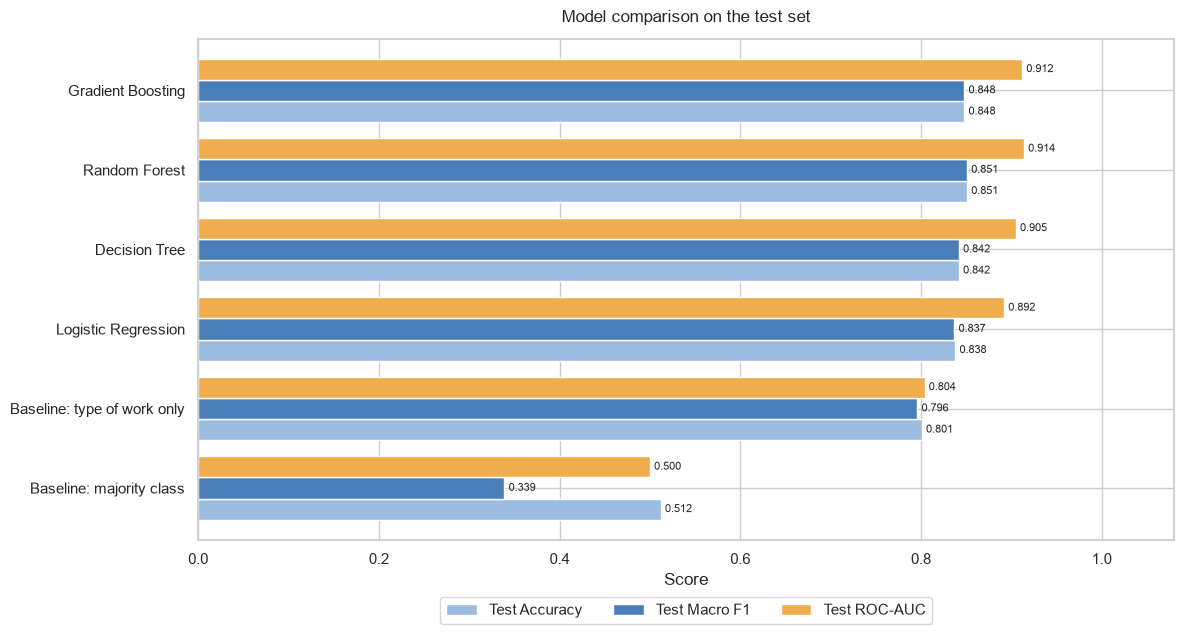

In [22]:
majority = int(y_train.mean() >= 0.5)
pred_major = np.full(len(y_test), majority)

rate = X_train.assign(on_time=y_train).groupby("type_of_work")["on_time"].mean()
prob_tow = X_test["type_of_work"].map(rate).fillna(y_train.mean())
pred_tow = (prob_tow >= 0.5).astype(int)

baselines = pd.DataFrame({
    "Test Accuracy": [accuracy_score(y_test, pred_major), accuracy_score(y_test, pred_tow)],
    "Test Macro F1": [f1_score(y_test, pred_major, average="macro"), f1_score(y_test, pred_tow, average="macro")],
    "Test ROC-AUC": [0.5, roc_auc_score(y_test, prob_tow)],
}, index=["Baseline: majority class", "Baseline: type of work only"])

comparison = pd.concat([baselines, results_df[["Test Accuracy", "Test Macro F1", "Test ROC-AUC"]]]).round(3)
display(comparison)

fig, ax = plt.subplots(figsize=(12, 6.5))
comparison.plot.barh(ax=ax, color=["#9bbbe0", "#4a7ebb", "#f0ad4e"], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=3, fontsize=8)
ax.set_xlim(0, 1.08)
ax.set_title("Model comparison on the test set", pad=12)
ax.set_xlabel("Score")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
plt.savefig(FIG_DIR / "19_model_comparison.png", dpi=150)
plt.show()

#### Every model clearly beats both baselines. Type of work alone already reaches 80% accuracy, and the models add about 4 to 5 points of accuracy and 0.09 to 0.11 of AUC by combining it with permit category, value, timing and location. Random forest is the best overall, with gradient boosting a close second.